# 주장과 근거의 관계

개선안의 한 문장은 무엇이 문제다 주장이 있고, 그 증거로 이런 숫자가 있다 근거로 구성되어있다. 근거가 왜 주장을 뒷받침하는지에 대한 설명이 있어야하고, 이 설명을 연결고리 라고 일컫는다.

데이터: 부산항만공사 선박 입출항집계, 해양수산부 선박관제정보
- 주장: 통제 해제 직후 관제의 입항 순서 지정 업무가 몰린다.
- 연결고리: 뒷받침 근거 데이터 입항 한건 -> 관제가 순서를 지정한 입항 건수
- 근거: 통제가 해제된 다음 날 가장 바쁜 한시간 입항 척수는 13척이었고, 평소에는 10척정도였다.

같은 근거가 어떤 주장은 잘 뒷받침하고, 어떤 주장은 전혀 뒷받침하지 못할 수 있다.

- 근거: 통제 해제 직후 들어온 컨테이너선의 항해시간이 직전 기간보다 17.6시간 길다.

- 주장: 통제 기간중에서는 바다에서 기다린 선박이 섞여있다.
- 연결고리: 항해 시간에는 부산항 앞 대기가 섞여 있다.

- 주장: 입항 순서를 미리 정하면 선박 대기가 줄어든다.
- 연결고리: 순서를 미리 정하면 대기의 총량이 줄어든다.

## 근거 매트릭스

근거 매트릭스 하나의 근거가 여러 주장을 뒷받침하기도 하고, 어떤 주장은 근거가 없기도 한데, 이러한 관계를 행열로 표현해놓은것을 의미한다. 주장이 행이되고, 근거가 열로 구성되어있다.



In [ ]:
!uv add pandas numpy matplotlib

In [25]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False # 한글폰트에서 -표시 깨짐방지

In [10]:
from matplotlib.colors import ListedColormap

claims = [ 'A1', 'A2', 'A3', 'B1', 'B2', 'D1' ]
# Q는 정량, S는 정성 근거
evidence_ids = [ 'Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'S1', 'S2', 'S3' ]

links = [
    ( 'A1', 'Q1', 1 ), ( 'A1', 'Q2', 1 ), ( 'A1', 'S1', 1 ),
    ( 'A2', 'Q3', 1 ),
    ( 'A3', 'Q4', -1 ), ( 'A3', 'Q5', -1 ), ( 'A3', 'S2', 1 ),
    ( 'B1', 'Q6', 1 ), ( 'B1', 'S3', 1 ),
    ( 'B2', 'S3', 1 ),
    ( 'D1', 'Q7', 1 ),
]

matrix = pd.DataFrame(0, index=claims, columns=evidence_ids)

for claim, ev, sign in links:
    matrix.loc[claim, ev] = sign

print(matrix.shape, (matrix != 0).sum().sum())

(6, 10) 11


In [11]:
cmap = ListedColormap(['#c8553d', 'white', '#3d7cc8'])

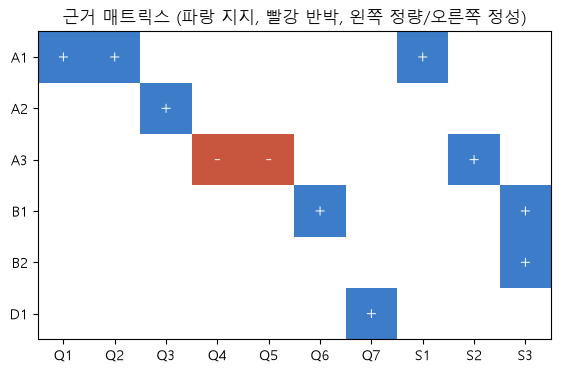

In [30]:
fig, ax = plt.subplots(figsize=(9, 4))

ax.imshow(matrix.values, cmap=cmap, vmin=-1, vmax=1)

for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        value = matrix.iloc[i, j]
        if value:
            ax.text(j, i, "+" if value > 0 else "-", ha="center", va="center", fontsize=13, color="white")

ax.set_xticks(range(len(evidence_ids)), evidence_ids)
ax.set_yticks(range(len(claims)), claims)

ax.set_title('근거 매트릭스 (파랑 지지, 빨강 반박, 왼쪽 정량/오른쪽 정성)')

plt.show()

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def load_dataset(filename, cols=None):
    BASE_DIR = './data'
    EXTENSION = '.csv'
    TARGET_PATH = f'{BASE_DIR}/{filename}{EXTENSION}'
    try:
        return pd.read_csv(TARGET_PATH)
    except FileNotFoundError:
        return None
    except UnicodeDecodeError:
        return pd.read_csv(TARGET_PATH, encoding='euc-kr', usecols=cols if cols else None)

## 입출항 집계

In [40]:
d004 = load_dataset('입출항', ['입항일시'])

d004['입항'] = pd.to_datetime(d004['입항일시'], format='%Y-%m-%d %H:%M', errors='coerce')
d004 = d004[d004['입항'].dt.year.between(2019, 2024)]

print(len(d004))

272861


## 관제정보

In [50]:
d012 = load_dataset('선박관제정보', cols=['관제항구', '입항일시', '상태구분'])
d012 = d012[(d012['관제항구'] == '부산') & (d012['상태구분'] != '삭제')]

d012['입항'] = pd.to_datetime(d012['입항일시'], errors='coerce')

d012.head()


,관제항구,입항일시,상태구분,입항
0,부산,2024-05-01 01:10:00,수정,2024-05-01 01:10:00
4,부산,2024-05-01 03:00:00,수정,2024-05-01 03:00:00
6,부산,2024-05-01 09:00:00,수정,2024-05-01 09:00:00
8,부산,2024-05-01 07:35:00,수정,2024-05-01 07:35:00
13,부산,2024-05-01 08:35:00,수정,2024-05-01 08:35:00


In [49]:
d012.info()

<class 'pandas.DataFrame'>
Index: 41936 entries, 0 to 176737
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   관제항구    41936 non-null  str           
 1   입항일시    41936 non-null  str           
 2   상태구분    41936 non-null  str           
 3   입항      41936 non-null  datetime64[us]
dtypes: datetime64[us](1), str(3)
memory usage: 1.6 MB


In [51]:
print(len(d012), d012['입항'].min().date(), d012['입항'].max().date())

41936 2024-05-01 2025-07-31
